1. Annual Distribution of Funding Status in LIS Publications

In [2]:
# ============================================================
# Import
# ============================================================

import pandas as pd
import ast

In [3]:
# ------------------------------------------------------------
# Load dataset
# ------------------------------------------------------------

df = pd.read_csv("LIS_data_cleaned_with_OND.csv")

In [4]:
# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    # Missing values
    if pd.isna(x):
        return []

    x = str(x).strip()

    # Empty or placeholder values
    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    # Convert string representation of a list
    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    # Fallback for semicolon-separated strings
    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

In [5]:
# ------------------------------------------------------------
# Function:
# Classify funding status for each paper
#
# Rules:
# 0 funders  -> Unfunded
# 1 funder   -> Single-funded
# 2+ funders -> Co-funded
# ------------------------------------------------------------

def classify_funding(x):

    funders = parse_funders(x)

    if len(funders) == 0:
        return "Unfunded"

    elif len(funders) == 1:
        return "Single-funded"

    else:
        return "Co-funded"

In [6]:
# ------------------------------------------------------------
# Create new variables
#
# Funder_List:
#   List of funding organizations
#
# Funder_Count:
#   Number of funding organizations
#
# Funding_Status:
#   Unfunded / Single-funded / Co-funded
# ------------------------------------------------------------

df["Funder_List"] = df["Funding_Details_OND"].apply(parse_funders)

df["Funder_Count"] = df["Funder_List"].apply(len)

df["Funding_Status"] = df["Funding_Details_OND"].apply(classify_funding)

In [7]:
# ------------------------------------------------------------
# Check classification results
# ------------------------------------------------------------

print(df["Funding_Status"].value_counts())

Unfunded         48653
Co-funded        18674
Single-funded    13467
Name: Funding_Status, dtype: int64


In [8]:
# ------------------------------------------------------------
# Annual count table
#
# Rows:
#   Year
#
# Columns:
#   Funding Status
# ------------------------------------------------------------

annual_counts = pd.crosstab(
    df["Year"],
    df["Funding_Status"]
)

# Ensure all categories exist
for col in [
    "Unfunded",
    "Single-funded",
    "Co-funded"
]:
    if col not in annual_counts.columns:
        annual_counts[col] = 0

annual_counts = annual_counts[
    [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]
]

In [9]:
# ------------------------------------------------------------
# Calculate total papers per year
# ------------------------------------------------------------

annual_counts["Total Papers"] = annual_counts.sum(axis=1)

In [10]:
# ------------------------------------------------------------
# Funded papers
#
# Funded = Single-funded + Co-funded
# ------------------------------------------------------------

annual_counts["Funded"] = (
    annual_counts["Single-funded"]
    + annual_counts["Co-funded"]
)

In [11]:
# ------------------------------------------------------------
# Calculate annual percentages
# ------------------------------------------------------------

annual_pct = (
    annual_counts.div(
        annual_counts["Total Papers"],
        axis=0
    ) * 100
)

In [12]:
# ------------------------------------------------------------
# Create integrated summary table
#
# Includes:
# - Counts (N)
# - Percentages (%)
#
# Recommended title:
# "Annual Distribution of Funding Status in LIS Publications"
# ------------------------------------------------------------

funding_summary = pd.DataFrame({

    "Total Papers":
        annual_counts["Total Papers"],

    "Unfunded N":
        annual_counts["Unfunded"],

    "Unfunded %":
        annual_pct["Unfunded"],

    "Single-funded N":
        annual_counts["Single-funded"],

    "Single-funded %":
        annual_pct["Single-funded"],

    "Co-funded N":
        annual_counts["Co-funded"],

    "Co-funded %":
        annual_pct["Co-funded"],

    "Funded N":
        annual_counts["Funded"],

    "Funded %":
        annual_pct["Funded"]
})

In [13]:
# ------------------------------------------------------------
# Round percentage values
# ------------------------------------------------------------

percentage_cols = [
    "Unfunded %",
    "Single-funded %",
    "Co-funded %",
    "Funded %"
]

funding_summary[percentage_cols] = (
    funding_summary[percentage_cols]
    .round(2)
)

In [14]:
# ------------------------------------------------------------
# Convert Year index into a normal column
# ------------------------------------------------------------

funding_summary = funding_summary.reset_index()

In [15]:
# ------------------------------------------------------------
# Display final summary table
# ------------------------------------------------------------

print(funding_summary)

    Year  Total Papers  Unfunded N  Unfunded %  Single-funded N  \
0   2014          5300        3865       72.92              722   
1   2015          5458        4118       75.45              717   
2   2016          6035        4623       76.60              578   
3   2017          6191        4335       70.02              761   
4   2018          6596        3785       57.38             1070   
5   2019          6845        3768       55.05             1173   
6   2020          8154        4602       56.44             1405   
7   2021          7913        4412       55.76             1467   
8   2022          8476        4743       55.96             1652   
9   2023          8801        4451       50.57             1792   
10  2024         11025        5951       53.98             2130   

    Single-funded %  Co-funded N  Co-funded %  Funded N  Funded %  
0             13.62          713        13.45      1435     27.08  
1             13.14          623        11.41      1340    

In [15]:
# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

funding_summary.to_csv(
    "Annual_Funding_Status_Summary.csv",
    index=False
)

2. Annual Percentage Distribution of Funding Status

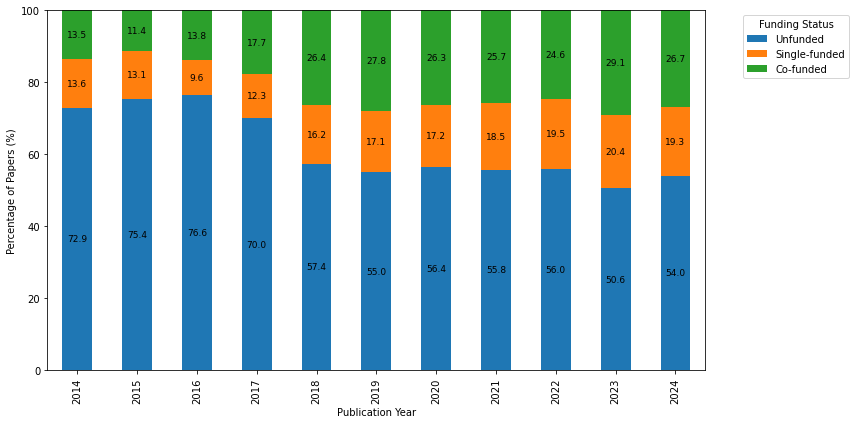

In [36]:
# ============================================================
# Figure 3.2: Stacked Percentage Bar Chart with Labels
# Annual Percentage Distribution of Funding Status
# ============================================================

import matplotlib.pyplot as plt

# Select percentage columns for plotting
plot_pct = annual_pct[
    ["Unfunded", "Single-funded", "Co-funded"]
].copy()

# Create stacked percentage bar chart
ax = plot_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

# ------------------------------------------------------------
# Add percentage labels inside each bar segment
# ------------------------------------------------------------

for i, year in enumerate(plot_pct.index):
    cumulative_height = 0

    for status in ["Unfunded", "Single-funded", "Co-funded"]:
        value = plot_pct.loc[year, status]

        # Label position: middle of each stacked segment
        label_y = cumulative_height + value / 2

        # Add label only when the segment is large enough
        if value >= 3:
            ax.text(
                i,
                label_y,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=9
            )

        cumulative_height += value
        
# ------------------------------------------------------------
# Customize figure
# ------------------------------------------------------------

plt.ylabel("Percentage of Papers (%)")
plt.xlabel("Publication Year")
# plt.title("Figure 3.2. Annual Percentage Distribution of Funding Status")
plt.ylim(0, 100)

plt.legend(
    title="Funding Status",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_2_Stacked_Percentage_Bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_2_Stacked_Percentage_Bar.pdf",
    bbox_inches="tight"
)

plt.show()

3. Funded vs. Unfunded Trend

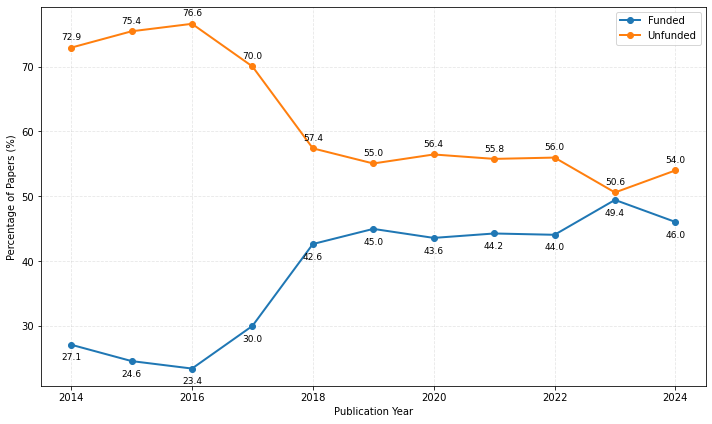

In [76]:
# ============================================================
# Figure 3.3: Funded vs. Unfunded Trend
# with Percentage Labels
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# ------------------------------------------------------------
# Plot lines
# ------------------------------------------------------------

plt.plot(
    annual_pct.index,
    annual_pct["Funded"],
    marker="o",
    linewidth=2,
    label="Funded"
)

plt.plot(
    annual_pct.index,
    annual_pct["Unfunded"],
    marker="o",
    linewidth=2,
    label="Unfunded"
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for year, value in zip(
    annual_pct.index,
    annual_pct["Funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, -15),
        ha="center",
        fontsize=9
    )

for year, value in zip(
    annual_pct.index,
    annual_pct["Unfunded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")
plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.3. Funded and Unfunded LIS Publications Over Time"
# )

plt.legend()

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded.pdf",
    bbox_inches="tight"
)

plt.show()

4. LOESS-Smoothed Funded Trend

In [37]:
import sys

!{sys.executable} -m pip install statsmodels

You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


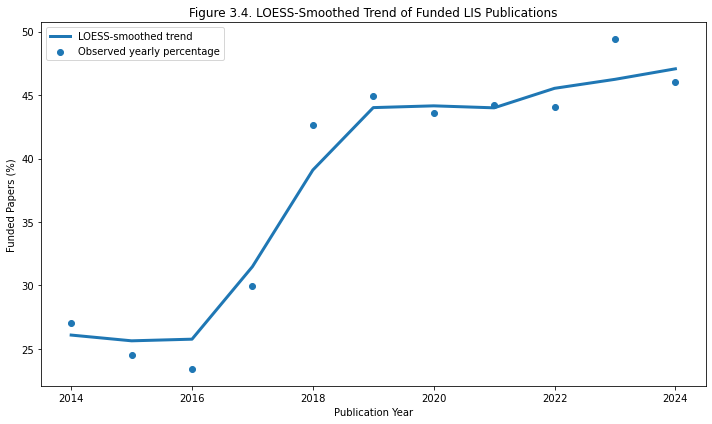

In [39]:
# ============================================================
# Figure 3.4: LOESS-Smoothed Funded Trend
# ============================================================

import statsmodels
from statsmodels.nonparametric.smoothers_lowess import lowess

loess_funded = lowess(
    endog=annual_pct["Funded"],
    exog=annual_pct.index,
    frac=0.5
)

plt.figure(figsize=(10, 6))

plt.scatter(
    annual_pct.index,
    annual_pct["Funded"],
    label="Observed yearly percentage"
)

plt.plot(
    loess_funded[:, 0],
    loess_funded[:, 1],
    linewidth=3,
    label="LOESS-smoothed trend"
)

plt.xlabel("Publication Year")
plt.ylabel("Funded Papers (%)")
plt.title("Figure 3.4. LOESS-Smoothed Trend of Funded LIS Publications")
plt.legend()
plt.tight_layout()
plt.show()

5. Single-funded vs. Co-funded

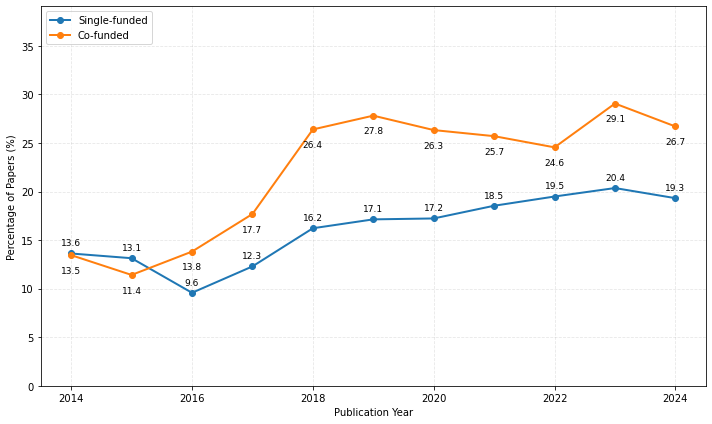

In [75]:
# ============================================================
# Figure 3.5
# Single-funded vs. Co-funded Trend
# with Percentage Labels
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# ------------------------------------------------------------
# Plot lines
# ------------------------------------------------------------

plt.plot(
    annual_pct.index,
    annual_pct["Single-funded"],
    marker="o",
    linewidth=2,
    label="Single-funded"
)

plt.plot(
    annual_pct.index,
    annual_pct["Co-funded"],
    marker="o",
    linewidth=2,
    label="Co-funded"
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for year, value in zip(
    annual_pct.index,
    annual_pct["Single-funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

for year, value in zip(
    annual_pct.index,
    annual_pct["Co-funded"]
):
    plt.annotate(
        f"{value:.1f}",
        (year, value),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")
plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.5. Single-funded and Co-funded LIS Publications Over Time"
# )

plt.ylim(
    0,
    max(
        annual_pct["Single-funded"].max(),
        annual_pct["Co-funded"].max()
    ) + 10
)

plt.legend(loc="upper left")

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding.pdf",
    bbox_inches="tight"
)

plt.show()

6. Linear Trend Test

In [52]:
# ============================================================
# Table 3.4: Linear Trend Test
#
# Purpose:
# Estimate the average annual percentage-point change
# for each funding category.
# ============================================================

from scipy.stats import linregress

trend_results = []

for col in [
    "Funded",
    "Unfunded",
    "Single-funded",
    "Co-funded"
]:

    slope, intercept, r_value, p_value, std_err = linregress(
        annual_pct.index,
        annual_pct[col]
    )

    trend_results.append({
        "Funding Category": col,
        "Slope": slope,
        "p-value": p_value,
        "R-squared": r_value ** 2,
        "Standard Error": std_err
    })

trend_table = pd.DataFrame(trend_results)

trend_table["Slope"] = trend_table["Slope"].round(3)
trend_table["p-value"] = trend_table["p-value"].round(4)
trend_table["R-squared"] = trend_table["R-squared"].round(3)
trend_table["Standard Error"] = trend_table["Standard Error"].round(3)

trend_table

,Funding Category,Slope,p-value,R-squared,Standard Error
0,Funded,2.597,0.0003,0.782,0.457
1,Unfunded,-2.597,0.0003,0.782,0.457
2,Single-funded,0.915,0.0004,0.765,0.169
3,Co-funded,1.682,0.0010,0.716,0.353


7. Single-funded vs. Co-funded Trend Visualization

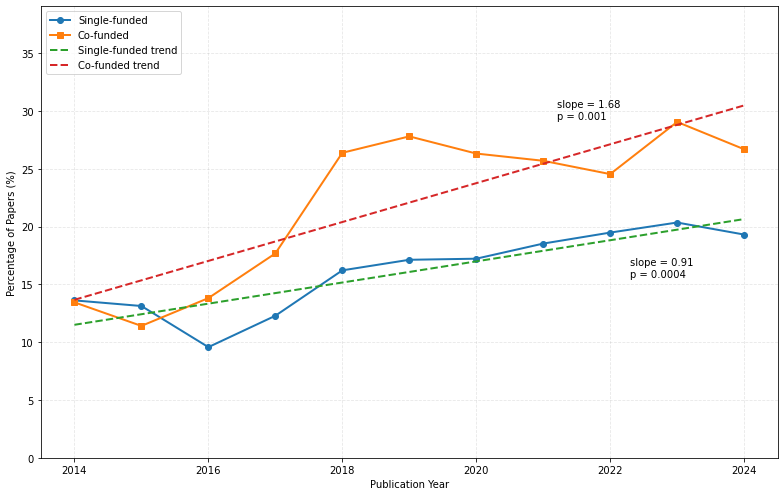

In [74]:
# ============================================================
# Figure 3.5
# Single-funded vs. Co-funded Trend
# with Linear Trend Lines
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

years = annual_pct.index.values

single = annual_pct["Single-funded"].values
cofund = annual_pct["Co-funded"].values

# ------------------------------------------------------------
# Linear Trend: Single-funded
# ------------------------------------------------------------

single_slope, single_intercept, single_r, single_p, single_se = (
    linregress(years, single)
)

single_trend = (
    single_intercept +
    single_slope * years
)

# ------------------------------------------------------------
# Linear Trend: Co-funded
# ------------------------------------------------------------

co_slope, co_intercept, co_r, co_p, co_se = (
    linregress(years, cofund)
)

co_trend = (
    co_intercept +
    co_slope * years
)

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

# ------------------------------------------------------------
# Observed Single-funded
# ------------------------------------------------------------

plt.plot(
    years,
    single,
    marker="o",
    linewidth=2,
    label="Single-funded"
)

# ------------------------------------------------------------
# Observed Co-funded
# ------------------------------------------------------------

plt.plot(
    years,
    cofund,
    marker="s",
    linewidth=2,
    label="Co-funded"
)

# ------------------------------------------------------------
# Trend Line: Single-funded
# ------------------------------------------------------------

plt.plot(
    years,
    single_trend,
    linestyle="--",
    linewidth=2,
    label=f"Single-funded trend"
    #     label=f"Single-funded trend (p={single_p:.4f})"
)

plt.text(
    0.80,
    0.40,
    f"slope = {single_slope:.2f}\n"
    f"p = {single_p:.4f}",
    transform=plt.gca().transAxes
)

# ------------------------------------------------------------
# Trend Line: Co-funded
# ------------------------------------------------------------

plt.plot(
    years,
    co_trend,
    linestyle="--",
    linewidth=2,
    label=f"Co-funded trend"
#     label=f"Co-funded trend (p={co_p:.3f})"

)

plt.text(
    0.70,
    0.75,
    f"slope = {co_slope:.2f}\n"
    f"p = {co_p:.3f}",
    transform=plt.gca().transAxes
)

# ------------------------------------------------------------
# Add labels: Single-funded
# ------------------------------------------------------------

# for year, value in zip(years, single):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, 10),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add labels: Co-funded
# ------------------------------------------------------------

# for year, value in zip(years, cofund):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, -15),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.5. Trends in Single-funded and Co-funded LIS Publications"
# )

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.ylim(
    0,
    max(
        annual_pct["Single-funded"].max(),
        annual_pct["Co-funded"].max()
    ) + 10
)

plt.legend(loc="upper left")

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_5_Single_vs_Cofunding_Trend.pdf",
    bbox_inches="tight"
)

plt.show()

8. Funded vs. Unfunded Trend Trend Visualization

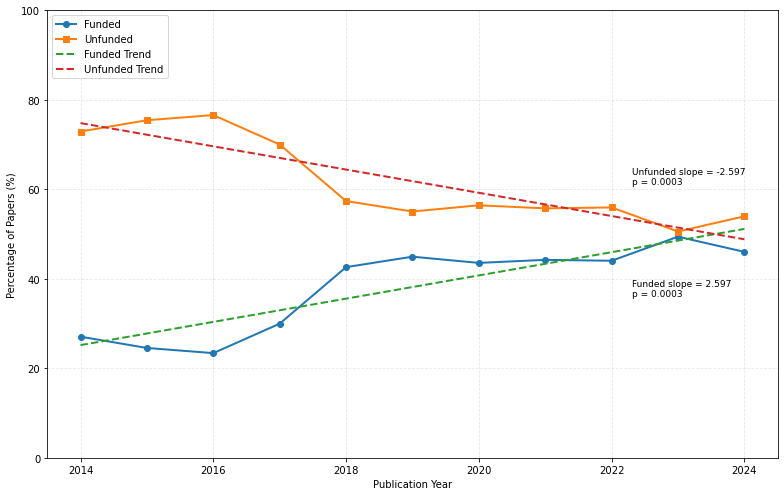

Funded
Slope = 2.597
p-value = 0.0003

Unfunded
Slope = -2.597
p-value = 0.0003


In [81]:
# ============================================================
# Figure 3.3
# Funded vs. Unfunded Trend
# with Percentage Labels and Linear Trend Lines
# ============================================================

import matplotlib.pyplot as plt
from scipy.stats import linregress

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

years = annual_pct.index.values

funded = annual_pct["Funded"].values
unfunded = annual_pct["Unfunded"].values

# ------------------------------------------------------------
# Linear Trend: Funded
# ------------------------------------------------------------

funded_slope, funded_intercept, funded_r, funded_p, funded_se = (
    linregress(years, funded)
)

funded_trend = (
    funded_intercept +
    funded_slope * years
)

# ------------------------------------------------------------
# Linear Trend: Unfunded
# ------------------------------------------------------------

unfunded_slope, unfunded_intercept, unfunded_r, unfunded_p, unfunded_se = (
    linregress(years, unfunded)
)

unfunded_trend = (
    unfunded_intercept +
    unfunded_slope * years
)

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

# ------------------------------------------------------------
# Observed Funded
# ------------------------------------------------------------

plt.plot(
    years,
    funded,
    marker="o",
    linewidth=2,
    label="Funded"
)

# ------------------------------------------------------------
# Observed Unfunded
# ------------------------------------------------------------

plt.plot(
    years,
    unfunded,
    marker="s",
    linewidth=2,
    label="Unfunded"
)

# ------------------------------------------------------------
# Funded Trend Line
# ------------------------------------------------------------

plt.plot(
    years,
    funded_trend,
    linestyle="--",
    linewidth=2,
    label=f"Funded Trend"
#     label=f"Funded Trend (p={funded_p:.3f})"
)

# ------------------------------------------------------------
# Unfunded Trend Line
# ------------------------------------------------------------

plt.plot(
    years,
    unfunded_trend,
    linestyle="--",
    linewidth=2,
    label=f"Unfunded Trend"
#     label=f"Unfunded Trend (p={unfunded_p:.3f})"
)

# ------------------------------------------------------------
# Add Percentage Labels: Funded
# ------------------------------------------------------------

# for year, value in zip(years, funded):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, -15),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add Percentage Labels: Unfunded
# ------------------------------------------------------------

# for year, value in zip(years, unfunded):

#     plt.annotate(
#         f"{value:.1f}",
#         (year, value),
#         textcoords="offset points",
#         xytext=(0, 8),
#         ha="center",
#         fontsize=9
#     )

# ------------------------------------------------------------
# Add Slope and p-value Information
# ------------------------------------------------------------

plt.text(
    0.80,
    0.40,
    f"Funded slope = {funded_slope:.3f}\n"
    f"p = {funded_p:.4f}",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top"
)

plt.text(
    0.80,
    0.65,
    f"Unfunded slope = {unfunded_slope:.3f}\n"
    f"p = {unfunded_p:.4f}",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top"
)

# ------------------------------------------------------------
# Figure Formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.3. Funded and Unfunded LIS Publications Over Time"
# )

plt.ylim(0, 100)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

plt.legend(
    loc="upper left",
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_3_Funded_vs_Unfunded_Trend.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print Statistics for Reporting
# ------------------------------------------------------------

print("Funded")
print(f"Slope = {funded_slope:.3f}")
print(f"p-value = {funded_p:.4f}")

print("\nUnfunded")
print(f"Slope = {unfunded_slope:.3f}")
print(f"p-value = {unfunded_p:.4f}")

9. Annual Distribution of Funding Status in LIS (Absolute count)

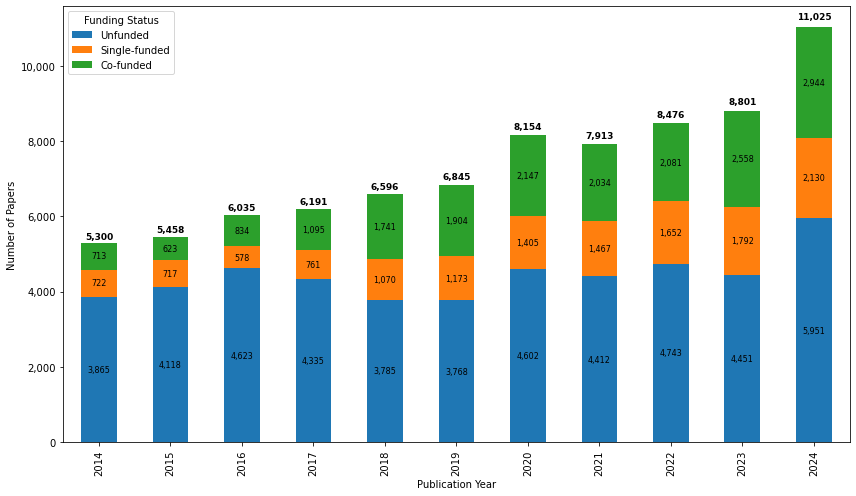

In [19]:
# ============================================================
# Figure 3.1
# Annual Distribution of Funding Status in LIS Publications
# (Absolute Counts)
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_counts = annual_counts[
    [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]
]

# ------------------------------------------------------------
# Create Figure
# ------------------------------------------------------------

ax = plot_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

# ------------------------------------------------------------
# Add count labels
# ------------------------------------------------------------

for i, year in enumerate(plot_counts.index):

    cumulative_height = 0

    for status in [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]:

        value = plot_counts.loc[year, status]

        if value > 0:

            ax.text(
                i,
                cumulative_height + value / 2,
                f"{int(value):,}",
                ha="center",
                va="center",
                fontsize=8
            )

        cumulative_height += value

# ------------------------------------------------------------
# Add total paper counts
# ------------------------------------------------------------

for i, year in enumerate(plot_counts.index):

    total = annual_counts.loc[year, "Total Papers"]

    ax.text(
        i,
        total + total * 0.02,
        f"{int(total):,}",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Publication Year")

plt.ylabel("Number of Papers")

from matplotlib.ticker import StrMethodFormatter

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

# plt.title(
#     "Figure 3.1. Annual Distribution of Funding Status in LIS Publications"
# )

plt.legend(
    title="Funding Status",
    loc="upper left",
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_1_Funding_Status_Counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_1_Funding_Status_Counts.pdf",
    bbox_inches="tight"
)

plt.show()

10. Funding Status by Journal

In [20]:
# ------------------------------------------------------------
# Journal list checking
# ------------------------------------------------------------

import pandas as pd

journal_df = pd.read_csv("journal_list.csv")

print(journal_df.columns)

journal_df.head()

Index(['Ranking', 'Journal_name'], dtype='object')


,Ranking,Journal_name
0,1,International Journal of Information Management
1,2,Information Systems Research
2,3,European Journal of Information Systems
3,4,Government Information Quarterly
4,5,International Journal of Information Managemen...


In [31]:
# ============================================================
# Clean journal names before merging
# ============================================================

lis_df = pd.read_csv(
    "LIS_data_cleaned_with_OND.csv"
)

journal_df = pd.read_csv(
    "journal_list.csv"
)

# ------------------------------------------------------------
# Standardize journal names
# ------------------------------------------------------------

lis_df["Source_title_clean"] = (
    lis_df["Source title"]
    .astype(str)
    .str.strip()
    .str.lower()
)

journal_df["Journal_name_clean"] = (
    journal_df["Journal_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# Create Quartiles
# ------------------------------------------------------------

journal_df["Quartile"] = pd.qcut(
    journal_df["Ranking"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

# ------------------------------------------------------------
# Merge
# ------------------------------------------------------------

lis_df = lis_df.merge(
    journal_df[
        [
            "Journal_name",
            "Ranking",
            "Quartile",
            "Journal_name_clean"
        ]
    ],
    left_on="Source_title_clean",
    right_on="Journal_name_clean",
    how="left"
)

# ------------------------------------------------------------
# Check unmatched papers
# ------------------------------------------------------------

print(
    "Unmatched papers:",
    lis_df["Quartile"].isna().sum()
)

Unmatched papers: 0


In [32]:
# ============================================================
# Table 3.2
# Distribution of Funding Status by Journal Quartile
# ============================================================

import pandas as pd
import ast

# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    if pd.isna(x):
        return []

    x = str(x).strip()

    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

# ------------------------------------------------------------
# Function:
# Classify funding status
#
# 0 funders  -> Unfunded
# 1 funder   -> Single-funded
# 2+ funders -> Co-funded
# ------------------------------------------------------------

def classify_funding(x):

    funders = parse_funders(x)

    if len(funders) == 0:
        return "Unfunded"

    elif len(funders) == 1:
        return "Single-funded"

    else:
        return "Co-funded"

# ------------------------------------------------------------
# Create funding variables
# ------------------------------------------------------------

lis_df["Funder_List"] = (
    lis_df["Funding_Details_OND"]
    .apply(parse_funders)
)

lis_df["Funder_Count"] = (
    lis_df["Funder_List"]
    .apply(len)
)

lis_df["Funding_Status"] = (
    lis_df["Funding_Details_OND"]
    .apply(classify_funding)
)

# ------------------------------------------------------------
# Check funding classification
# ------------------------------------------------------------

print(lis_df["Funding_Status"].value_counts())

# ------------------------------------------------------------
# Create count table by journal quartile
# ------------------------------------------------------------

quartile_counts = pd.crosstab(
    lis_df["Quartile"],
    lis_df["Funding_Status"]
)

# Ensure all funding status columns exist
for col in [
    "Unfunded",
    "Single-funded",
    "Co-funded"
]:
    if col not in quartile_counts.columns:
        quartile_counts[col] = 0

quartile_counts = quartile_counts[
    [
        "Unfunded",
        "Single-funded",
        "Co-funded"
    ]
]

# ------------------------------------------------------------
# Calculate total papers and funded papers
# ------------------------------------------------------------

quartile_counts["Total Papers"] = (
    quartile_counts.sum(axis=1)
)

quartile_counts["Funded"] = (
    quartile_counts["Single-funded"]
    +
    quartile_counts["Co-funded"]
)

# ------------------------------------------------------------
# Calculate percentages
# ------------------------------------------------------------

quartile_pct = (
    quartile_counts.div(
        quartile_counts["Total Papers"],
        axis=0
    ) * 100
)

# ------------------------------------------------------------
# Create integrated summary table
# ------------------------------------------------------------

quartile_summary = pd.DataFrame({

    "Total Papers":
        quartile_counts["Total Papers"],

    "Unfunded N":
        quartile_counts["Unfunded"],

    "Unfunded %":
        quartile_pct["Unfunded"],

    "Single-funded N":
        quartile_counts["Single-funded"],

    "Single-funded %":
        quartile_pct["Single-funded"],

    "Co-funded N":
        quartile_counts["Co-funded"],

    "Co-funded %":
        quartile_pct["Co-funded"],

    "Funded N":
        quartile_counts["Funded"],

    "Funded %":
        quartile_pct["Funded"]
})

# ------------------------------------------------------------
# Round percentage columns only
# ------------------------------------------------------------

percentage_cols = [
    "Unfunded %",
    "Single-funded %",
    "Co-funded %",
    "Funded %"
]

quartile_summary[percentage_cols] = (
    quartile_summary[percentage_cols]
    .round(2)
)

# ------------------------------------------------------------
# Convert Quartile index into a normal column
# ------------------------------------------------------------

quartile_summary = (
    quartile_summary
    .reset_index()
)

# ------------------------------------------------------------
# Display final table
# ------------------------------------------------------------

quartile_summary

Unfunded         48653
Co-funded        18674
Single-funded    13467
Name: Funding_Status, dtype: int64


,Quartile,Total Papers,Unfunded N,Unfunded %,Single-funded N,Single-funded %,Co-funded N,Co-funded %,Funded N,Funded %
0,Q1,40645,19241,47.34,8194,20.16,13210,32.50,21404,52.66
1,Q2,13683,9752,71.27,1996,14.59,1935,14.14,3931,28.73
2,Q3,14731,10159,68.96,2126,14.43,2446,16.60,4572,31.04
3,Q4,11735,9501,80.96,1151,9.81,1083,9.23,2234,19.04


In [33]:
# ------------------------------------------------------------
# Save final table
# ------------------------------------------------------------

quartile_summary.to_csv(
    "Table_3_2_Funding_Status_by_Journal_Quartile.csv",
    index=False
)

11. Funded Rate by Quartile

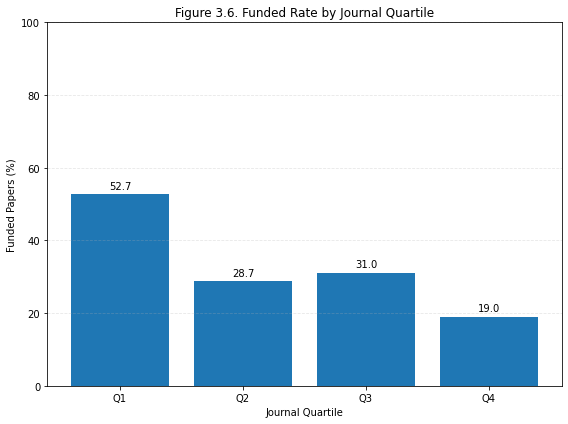

In [34]:
# ============================================================
# Figure 3.6
# Funded Rate by Journal Quartile
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_df = quartile_summary.copy()

# Ensure quartile order
plot_df["Quartile"] = pd.Categorical(
    plot_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

plot_df = plot_df.sort_values("Quartile")

# ------------------------------------------------------------
# Create bar chart
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

bars = plt.bar(
    plot_df["Quartile"],
    plot_df["Funded %"]
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    plot_df["Funded %"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

plt.xlabel("Journal Quartile")
plt.ylabel("Funded Papers (%)")

plt.title(
    "Figure 3.6. Funded Rate by Journal Quartile"
)

plt.ylim(0, 100)

plt.grid(
    axis="y",
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_6_Funded_Rate_by_Journal_Quartile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_6_Funded_Rate_by_Journal_Quartile.pdf",
    bbox_inches="tight"
)

plt.show()

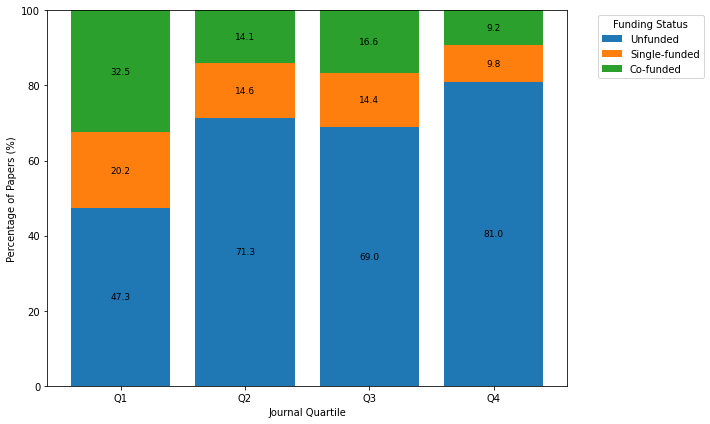

In [39]:
# ============================================================
# Figure 3.6
# Funding Status Distribution by Journal Quartile
# ============================================================

import matplotlib.pyplot as plt

plot_df = quartile_summary.copy()

plot_df["Quartile"] = pd.Categorical(
    plot_df["Quartile"],
    categories=["Q1","Q2","Q3","Q4"],
    ordered=True
)

plot_df = plot_df.sort_values("Quartile")

# ------------------------------------------------------------
# Create stacked bar chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10,6))

ax.bar(
    plot_df["Quartile"],
    plot_df["Unfunded %"],
    label="Unfunded"
)

ax.bar(
    plot_df["Quartile"],
    plot_df["Single-funded %"],
    bottom=plot_df["Unfunded %"],
    label="Single-funded"
)

ax.bar(
    plot_df["Quartile"],
    plot_df["Co-funded %"],
    bottom=(
        plot_df["Unfunded %"] +
        plot_df["Single-funded %"]
    ),
    label="Co-funded"
)

# ------------------------------------------------------------
# Add percentage labels
# ------------------------------------------------------------

for i, row in plot_df.iterrows():

    unfunded = row["Unfunded %"]
    single = row["Single-funded %"]
    cofund = row["Co-funded %"]

    ax.text(
        i,
        unfunded/2,
        f"{unfunded:.1f}",
        ha="center",
        va="center",
        fontsize=9
    )

    ax.text(
        i,
        unfunded + single/2,
        f"{single:.1f}",
        ha="center",
        va="center",
        fontsize=9
    )

    ax.text(
        i,
        unfunded + single + cofund/2,
        f"{cofund:.1f}",
        ha="center",
        va="center",
        fontsize=9
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xlabel("Journal Quartile")

plt.ylabel("Percentage of Papers (%)")

# plt.title(
#     "Figure 3.6. Funding Status Distribution by Journal Quartile"
# )

plt.ylim(0,100)

# plt.legend(
#     title="Funding Status",
#     loc="upper right",
#     frameon=True
# )

plt.legend(
    title="Funding Status",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_6_Funding_Status_by_Quartile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_6_Funding_Status_by_Quartile.pdf",
    bbox_inches="tight"
)

plt.show()

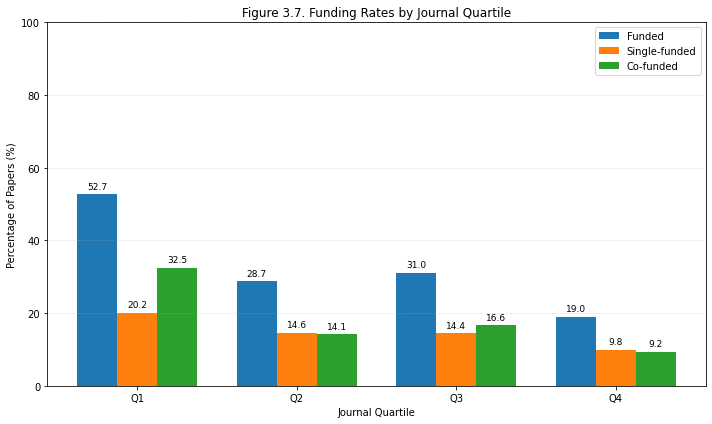

In [48]:
# ============================================================
# Figure 3.7
# Funded, Single-funded, and Co-funded Rates by Journal Quartile
# Grouped Bar Chart
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_df = quartile_summary.copy()

plot_df["Quartile"] = pd.Categorical(
    plot_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

plot_df = plot_df.sort_values("Quartile")

quartiles = plot_df["Quartile"].astype(str).values

funded = plot_df["Funded %"].values
single = plot_df["Single-funded %"].values
cofund = plot_df["Co-funded %"].values

# ------------------------------------------------------------
# Bar positions
# ------------------------------------------------------------

x = np.arange(len(quartiles))
width = 0.25

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width,
    funded,
    width,
    label="Funded"
)

bars2 = ax.bar(
    x,
    single,
    width,
    label="Single-funded"
)

bars3 = ax.bar(
    x + width,
    cofund,
    width,
    label="Co-funded"
)

# ------------------------------------------------------------
# Add value labels
# ------------------------------------------------------------

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel("Journal Quartile")
ax.set_ylabel("Percentage of Papers (%)")

ax.set_title(
    "Figure 3.7. Funding Rates by Journal Quartile"
)

ax.set_xticks(x)
ax.set_xticklabels(quartiles)

ax.set_ylim(0, 100)

ax.grid(
    axis="y",
    alpha=0.3,
    linestyle="--"
)

ax.legend(
    loc="upper right",
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_7_Funding_Rates_by_Journal_Quartile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_7_Funding_Rates_by_Journal_Quartile.pdf",
    bbox_inches="tight"
)

plt.show()

12. Chi-square Test

In [44]:
# ============================================================
# Chi-square Test
# Journal Quartile × Funding Status
# ============================================================

from scipy.stats import chi2_contingency
import pandas as pd

# ------------------------------------------------------------
# Create 4 × 2 contingency table
# ------------------------------------------------------------

chi_table = quartile_counts[
    [
        "Funded",
        "Unfunded"
    ]
].copy()

chi_table = chi_table.loc[
    ["Q1", "Q2", "Q3", "Q4"]
]

print("Contingency Table:")
print(chi_table)

# ------------------------------------------------------------
# Chi-square test of independence
# ------------------------------------------------------------

chi2, p, dof, expected = chi2_contingency(chi_table)

print("\nChi-square Test Results")
print(f"Chi-square statistic = {chi2:.3f}")
print(f"Degrees of freedom = {dof}")
# print(f"p-value = {p:.10f}")
print(f"{p:.20e}")

# ------------------------------------------------------------
# Expected frequencies
# ------------------------------------------------------------

expected_df = pd.DataFrame(
    expected,
    index=chi_table.index,
    columns=chi_table.columns
)

print("\nExpected Frequencies:")
print(expected_df.round(2))

Contingency Table:
Funding_Status  Funded  Unfunded
Quartile                        
Q1               21404     19241
Q2                3931      9752
Q3                4572     10159
Q4                2234      9501

Chi-square Test Results
Chi-square statistic = 6090.390
Degrees of freedom = 3
0.00000000000000000000e+00

Expected Frequencies:
Funding_Status    Funded  Unfunded
Quartile                          
Q1              16169.16  24475.84
Q2               5443.29   8239.71
Q3               5860.20   8870.80
Q4               4668.35   7066.65


In [46]:
# ============================================================
# Effect Size: Cramer's V
# ============================================================

import numpy as np

n = chi_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(chi_table.shape) - 1))
)

print(f"\nCramer's V = {cramers_v:.3f}")


Cramer's V = 0.275


In [47]:
print(quartile_summary[
    [
        "Quartile",
        "Funded %",
        "Single-funded %",
        "Co-funded %"
    ]
])

print("Chi-square =", chi2)

print("Cramer's V =", cramers_v)

  Quartile  Funded %  Single-funded %  Co-funded %
0       Q1     52.66            20.16        32.50
1       Q2     28.73            14.59        14.14
2       Q3     31.04            14.43        16.60
3       Q4     19.04             9.81         9.23
Chi-square = 6090.390452995488
Cramer's V = 0.2745573111756948


13. Logistic regression

In [49]:
# ============================================================
# Logistic Regression
# Funded Status ~ Journal Ranking
# ============================================================

import statsmodels.api as sm
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Prepare regression dataset
# ------------------------------------------------------------

reg_df = lis_df.copy()

# Keep rows with valid Ranking and Funding_Status
reg_df = reg_df[
    reg_df["Ranking"].notna() &
    reg_df["Funding_Status"].notna()
].copy()

# ------------------------------------------------------------
# Dependent variable
#
# 1 = Funded
# 0 = Unfunded
# ------------------------------------------------------------

reg_df["Funded_binary"] = np.where(
    reg_df["Funding_Status"] == "Unfunded",
    0,
    1
)

# ------------------------------------------------------------
# Independent variable
#
# Ranking:
# Lower value means higher-ranked journal
# ------------------------------------------------------------

X = reg_df[["Ranking"]]

X = sm.add_constant(X)

y = reg_df["Funded_binary"]

# ------------------------------------------------------------
# Fit logistic regression model
# ------------------------------------------------------------

logit_model = sm.Logit(y, X)

logit_result = logit_model.fit()

print(logit_result.summary())

Optimization terminated successfully.
         Current function value: 0.636876
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          Funded_binary   No. Observations:                80794
Model:                          Logit   Df Residuals:                    80792
Method:                           MLE   Df Model:                            1
Date:                Mon, 08 Jun 2026   Pseudo R-squ.:                 0.05243
Time:                        14:27:10   Log-Likelihood:                -51456.
converged:                       True   LL-Null:                       -54303.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2899      0.012     24.481      0.000       0.267       0.313
Ranking       -0.0142      0.

In [50]:
# ============================================================
# Odds Ratio Table
# ============================================================

params = logit_result.params
conf = logit_result.conf_int()
pvalues = logit_result.pvalues

odds_ratios = np.exp(params)
conf_odds = np.exp(conf)

or_table = pd.DataFrame({
    "Coefficient": params,
    "Odds Ratio": odds_ratios,
    "CI Lower": conf_odds[0],
    "CI Upper": conf_odds[1],
    "p-value": pvalues
})

or_table = or_table.round(4)

or_table

,Coefficient,Odds Ratio,CI Lower,CI Upper,p-value
const,0.2899,1.3362,1.3056,1.3676,0.0
Ranking,-0.0142,0.9859,0.9855,0.9863,0.0


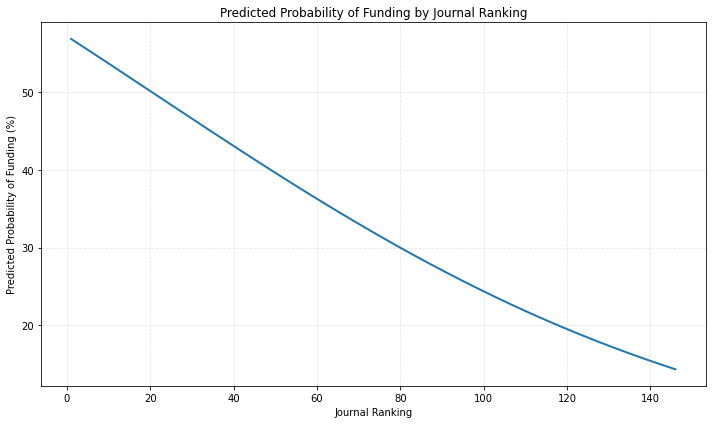

In [51]:
# ============================================================
# Predicted Probability of Funding by Journal Ranking
# ============================================================

ranking_range = pd.DataFrame({
    "Ranking": np.arange(
        reg_df["Ranking"].min(),
        reg_df["Ranking"].max() + 1
    )
})

ranking_range_X = sm.add_constant(ranking_range)

ranking_range["Predicted_Funded_Probability"] = (
    logit_result.predict(ranking_range_X)
)

# ------------------------------------------------------------
# Plot predicted probability
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    ranking_range["Ranking"],
    ranking_range["Predicted_Funded_Probability"] * 100,
    linewidth=2
)

plt.xlabel("Journal Ranking")
plt.ylabel("Predicted Probability of Funding (%)")

plt.title(
    "Predicted Probability of Funding by Journal Ranking"
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

plt.savefig(
    "Predicted_Funding_Probability_by_Journal_Ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Predicted_Funding_Probability_by_Journal_Ranking.pdf",
    bbox_inches="tight"
)

plt.show()